# Tutorial 1: TedSim

This tutorial demonstrates how to apply DeepTracing to simulated single-cell lineage-tracing data generated by TedSim. The workflow covers data preparation, lineage distance calculation, model training, representation extraction, and UMAP visualization.

The original simulation data can be generated using [`generate.R`](generate.R). Place the generated files in the `data/0.5/` directory under `experiments/TedSim/` before running this tutorial.

Run this notebook from the `experiments/TedSim/` directory. The model implementation and supporting functions are provided in the corresponding Python modules.

## Setup and paths

In [1]:
from pathlib import Path
from time import time
from importlib.metadata import version, PackageNotFoundError
import pickle

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import torch

from data_processing import create_anndata, prepare_data, truncate_tree, create_adata_from_tree, subtree_clusters
from DeepTracing import DEEPTRACING
from preprocess import normalize, inducing_points_select, barcode_distances_between_arrays
from plotting_and_evaluation_metrics import (
    add_embeddings,
    plot_show_adata,
    plot_umap_embeddings,
)

%matplotlib inline

# Paths are relative to experiments/TedSim/ (the notebook working directory).
WORK_DIR = Path.cwd().resolve()
p_a = 0.5
PA_NAME = f"p_a_{p_a}"
DATA_DIR = WORK_DIR / "data"
PROCESSED_DIR = WORK_DIR / "output_data"
RESULTS_DIR = WORK_DIR / "results"
TRAIN_DIR = RESULTS_DIR / "train" / PA_NAME
FIGURES_DIR = RESULTS_DIR / "Figures" / PA_NAME

for folder in (PROCESSED_DIR, TRAIN_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RAW_ADATA_FILE = PROCESSED_DIR / f"raw_adata_{p_a}.h5ad"
PREPROCESSED_FILE = PROCESSED_DIR / f"preprocessed_adata_{p_a}.h5ad"
TREE_FILE = PROCESSED_DIR / f"tree_{p_a}.pkl"
MODEL_FILE = TRAIN_DIR / "model.pt"
FINAL_LATENT_FILE = TRAIN_DIR / "final_latent.txt"
GP_LATENT_FILE = TRAIN_DIR / "gp_latent.txt"
GAUSSIAN_LATENT_FILE = TRAIN_DIR / "gaussian_latent.txt"

print("Working directory:", WORK_DIR)
print("Training results:", TRAIN_DIR)

Working directory: /data/data2/wenyuhong/DeepTracing/experiments/TedSim
Training results: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/train/p_a_0.5


## Model configuration

In [2]:
class Args(object):
    def __init__(self):
        self.data_file = str(PROCESSED_DIR)
        self.select_genes = 0
        self.batch_size = "auto"
        self.maxiter = 5000
        self.train_size = 0.95
        self.patience = 20
        self.lr = 1e-3
        self.weight_decay = 1e-6
        self.noise = 0
        self.dropoutE = 0
        self.dropoutD = 0
        self.encoder_layers = [128, 64]
        self.GP_dim = 5
        self.Normal_dim = 5
        self.decoder_layers = [128]
        self.dynamicVAE = True
        self.init_beta_gaussian = 5
        self.min_beta_gaussian = 1
        self.max_beta_gaussian = 10
        self.init_beta_gp = 10
        self.min_beta_gp = 4
        self.max_beta_gp = 25
        self.KL_loss = 0.025
        self.num_samples = 1
        self.fix_inducing_points = True
        self.inducing_point_nums = None
        self.fixed_gp_params = False
        self.loc_range = 20.
        self.kernel_scale = 20.
        self.denoised_counts_file = "denoised_counts.txt"
        self.num_denoise_samples = 10000
        self.device = "cuda:1"

args = Args()

## Data Preprocessing

In [3]:
TEDSIM_SOURCE_DIR = DATA_DIR / str(p_a)
if not TEDSIM_SOURCE_DIR.is_dir():
    raise FileNotFoundError(
        f"TedSim source directory not found: {TEDSIM_SOURCE_DIR}. "
        "Place the original TedSim inputs there before running this section."
    )

adata_raw_generated = create_anndata(TEDSIM_SOURCE_DIR, p_a=p_a)
sc.write(RAW_ADATA_FILE, adata_raw_generated)
print("Raw expression:", adata_raw_generated.shape)

/data/data2/wenyuhong/miniconda3/envs/DeepTracing/lib/python3.9/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/data/data2/wenyuhong/miniconda3/envs/DeepTracing/lib/python3.9/site-packages/anndata/_core/anndata.py:183: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Raw expression: (8190, 500)


In [4]:
adata_raw = sc.read(RAW_ADATA_FILE)

tree = prepare_data(str(RAW_ADATA_FILE))
with TREE_FILE.open("wb") as f:
    pickle.dump(tree, f)

all_data = truncate_tree(tree, depth=12)
adata_all = create_adata_from_tree(all_data)
mask = adata_all.obs["node_depth"].isin([12])
adata_need = adata_all[mask, :].copy()
adata_need.X = np.array(adata_need.X) if isinstance(adata_need.X, pd.Series) else adata_need.X
adata_need = subtree_clusters(adata_need, tree, 4, "subtree")

adata_need.obs.index = adata_need.obs.index.astype(str)
for col in adata_need.obs.columns:
    if adata_need.obs[col].dtype == "object":
        adata_need.obs[col] = adata_need.obs[col].astype(str)

adata_need.write(PREPROCESSED_FILE)
print("Preprocessed data:", adata_need)

/data/data2/wenyuhong/miniconda3/envs/DeepTracing/lib/python3.9/site-packages/anndata/__init__.py:51: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/data2/wenyuhong/miniconda3/envs/DeepTracing/lib/python3.9/site-packages/anndata/__init__.py:51: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


rna.shape[0]: 8190
Type of rna.shape[0]: <class 'int'>
Preprocessed data: AnnData object with n_obs × n_vars = 4096 × 500
    obs: 'time', 'node_depth', 'cluster', 'subtree'
    obsm: 'barcodes'


In [5]:
adata = sc.read(PREPROCESSED_FILE)
print(adata)

# Keep the original normalization options.
# sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=4000, subset=True)
adata = normalize(
    adata,
    size_factors=True,
    normalize_input=True,
    logtrans_input=True,
)

AnnData object with n_obs × n_vars = 4096 × 500
    obs: 'time', 'node_depth', 'cluster', 'subtree'
    obsm: 'barcodes'


/data/data2/wenyuhong/miniconda3/envs/DeepTracing/lib/python3.9/site-packages/anndata/__init__.py:51: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


In [6]:
barcodes_all = np.asarray(adata.obsm["barcodes"])  # (N, 32)
unique_barcodes, inverse_indices = np.unique(barcodes_all, axis=0, return_inverse=True)

indices_all = inverse_indices

inducing_points = inducing_points_select(adata=adata, barcodes=barcodes_all,
                                     select_feature=adata.obs['subtree'],
                                     all_indices=inverse_indices, CELLS_PER_ADDITIONAL_POINT=100)
initial_inducing_points = np.array(inducing_points)
print(initial_inducing_points)
print(f"total number of induction points: {len(initial_inducing_points)}")

[3349 3275 3443 3313 1578 3393  133 1206 1743 1733  304  288   23  103
  294  150 2570  904  929 2712 2662  955 2573 1010 2147  825 2363 2229
 2152  813  755 3218 3060 3610 3596 3048  162 1739 2738  268 2423 1161
 1367 1385 1256 1403 1653 1190 2778 2805 2009  559  635  580 1946  677
 2872   57  452 2929 1701 1128   54 1624]
total number of induction points: 64


In [7]:
DISTANCE_FILE = TRAIN_DIR / f"unique_distance_matrix_{p_a}.npy"
if not DISTANCE_FILE.is_file():
    unique_distance_matrix = barcode_distances_between_arrays(unique_barcodes, unique_barcodes)
    np.save(DISTANCE_FILE, unique_distance_matrix)
unique_distance_matrix = np.load(DISTANCE_FILE)
print("Lineage distance matrix:", unique_distance_matrix.shape)

Lineage distance matrix: (3725, 3725)


## Model Training

In [8]:
if args.batch_size == "auto":
    if adata.X.shape[0] <= 1024:
        args.batch_size = 128
    elif adata.X.shape[0] <= 2048:
        args.batch_size = 256
    else:
        args.batch_size = 512
else:
    args.batch_size = int(args.batch_size)
print(args)

In [9]:
model = DEEPTRACING(input_dim=adata.n_vars, GP_dim=args.GP_dim, Normal_dim=args.Normal_dim, encoder_layers=args.encoder_layers, decoder_layers=args.decoder_layers,
        noise=args.noise, encoder_dropout=args.dropoutE, decoder_dropout=args.dropoutD, distance=unique_distance_matrix,
        initial_inducing_points=initial_inducing_points, fixed_inducing_points=args.fix_inducing_points,
        fixed_gp_params=args.fixed_gp_params, kernel_scale=args.kernel_scale, N_train=adata.n_obs, KL_loss=args.KL_loss, dynamicVAE=args.dynamicVAE,
        init_beta_gaussian=args.init_beta_gaussian, min_beta_gaussian=args.min_beta_gaussian, max_beta_gaussian=args.max_beta_gaussian,
        init_beta_gp=args.init_beta_gp, min_beta_gp=args.min_beta_gp, max_beta_gp=args.max_beta_gp,
        dtype=torch.float64, device=args.device)

print(str(model))

DEEPTRACING(
  (svgp): SVGP(
    (kernel): Kernel()
  )
  (encoder): DenseEncoder(
    (layers): Sequential(
      (0): Linear(in_features=500, out_features=128, bias=True)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ELU(alpha=1.0)
      (3): Linear(in_features=128, out_features=64, bias=True)
      (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ELU(alpha=1.0)
    )
    (enc_mu): Linear(in_features=64, out_features=10, bias=True)
    (enc_var): Linear(in_features=64, out_features=10, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=10, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ELU(alpha=1.0)
  )
  (dec_mean): Sequential(
    (0): Linear(in_features=128, out_features=500, bias=True)
    (1): MeanAct()
  )
  (NB_loss): NBLoss()
)


Training


/data/data2/wenyuhong/DeepTracing/experiments/TedSim/VAE_utils.py:75: UserWarning: Specified kernel cache directory could not be created! This disables kernel caching. Specified directory is /data/data2/wenyuhong/.cache/torch/kernels. This warning will appear only once per process. (Triggered internally at  /opt/conda/conda-bld/pytorch_1646756402876/work/aten/src/ATen/native/cuda/jit_utils.cpp:860.)
  t1 = torch.lgamma(disp+eps) + torch.lgamma(x+1.0) - torch.lgamma(x+disp+eps)


Training epoch 1, ELBO:6328.22820239, NB loss:6316.97940691, GP KLD loss:0.06885970, Gaussian KLD loss:2.06886518, noise regularization:0.000000
Current beta_gaussian 5.228286724623221
Current beta_gp 10.22828672462322
Current kernel scale tensor([19.9930], device='cuda:1')
Training epoch 1, validating ELBO:5851.52282138
Training epoch 2, ELBO:5523.70440067, NB loss:5500.25766519, GP KLD loss:0.15045364, Gaussian KLD loss:4.03487309, noise regularization:0.000000
Current beta_gaussian 5.707360780288871
Current beta_gp 10.70736078028887
Current kernel scale tensor([19.9860], device='cuda:1')
Training epoch 2, validating ELBO:5188.04009111
Training epoch 3, ELBO:4911.94220167, NB loss:4875.67553393, GP KLD loss:0.20388587, Gaussian KLD loss:5.63221246, noise regularization:0.000000
Current beta_gaussian 6.501596906204632
Current beta_gp 11.50159690620463
Current kernel scale tensor([19.9789], device='cuda:1')
Training epoch 3, validating ELBO:4641.95260149
Training epoch 4, ELBO:4402.241

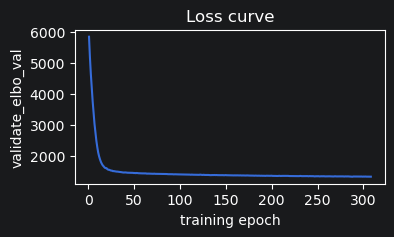

In [10]:
if not MODEL_FILE.exists():
    t0 = time()
    model.train_model(
        indices=indices_all,
        ncounts=adata.X,
        raw_counts=adata.raw.X,
        size_factors=adata.obs["size_factors"].to_numpy(),
        lr=args.lr,
        weight_decay=args.weight_decay,
        batch_size=args.batch_size,
        num_samples=args.num_samples,
        train_size=args.train_size,
        maxiter=args.maxiter,
        patience=args.patience,
        save_model=True,
        model_weights=str(MODEL_FILE),
    )
    print("Training time: %d seconds." % int(time() - t0))
else:
    model.load_model(str(MODEL_FILE))
    print("Loaded checkpoint:", MODEL_FILE)

model.curve_loss()

In [11]:
final_latent, gp_latent, gaussian_latent = model.batching_latent_samples(
    X=indices_all,
    Y=adata.X,
    batch_size=adata.X.shape[0],
)
np.savetxt(FINAL_LATENT_FILE, final_latent, delimiter=",")
np.savetxt(GP_LATENT_FILE, gp_latent, delimiter=",")
np.savetxt(GAUSSIAN_LATENT_FILE, gaussian_latent, delimiter=",")
print("Saved embeddings to:", TRAIN_DIR)

Saved embeddings to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/train/p_a_0.5


## Visualization

In [12]:
matplotlib.rcdefaults()
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   'white',
    'savefig.facecolor': 'white',
    'savefig.edgecolor': 'none',
    'savefig.transparent': False,

    'text.color':       'black',
    'axes.labelcolor':  'black',
    'axes.edgecolor':   'black',
    'xtick.color':      'black',
    'ytick.color':      'black',

    'legend.facecolor': 'white',
    'legend.edgecolor': 'black',
    'legend.frameon':   False,
})

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.5/adata_cluster.pdf


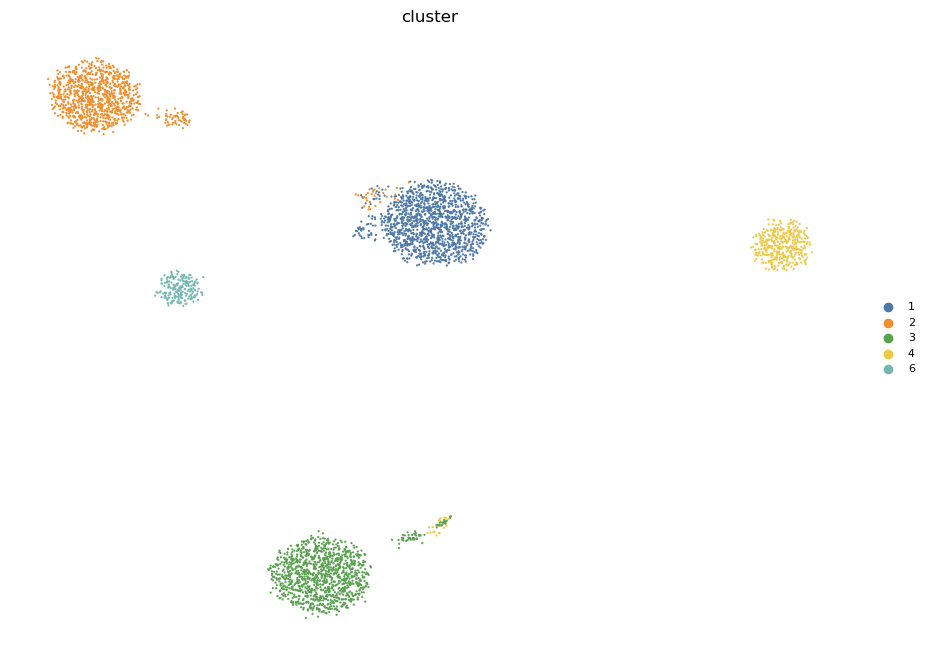

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.5/adata_subtree.pdf


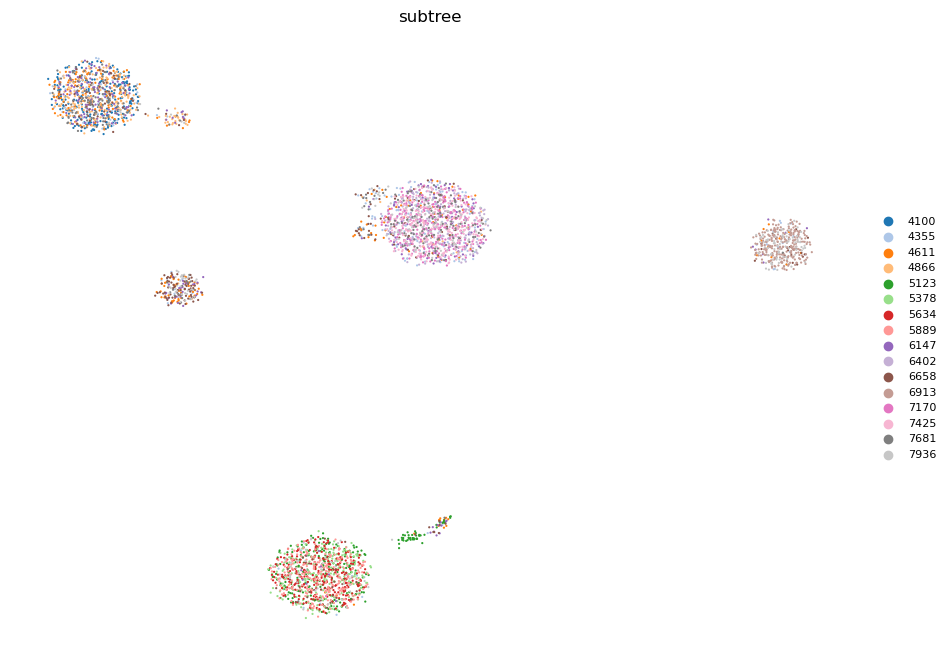

In [13]:
adata.obs["cluster"] = adata.obs["cluster"].astype("category")
adata.obs["subtree"] = adata.obs["subtree"].astype("category")

plot_show_adata(adata, color_feature="cluster", size=10, output_dir=FIGURES_DIR)
plot_show_adata(adata, color_feature="subtree", size=10, output_dir=FIGURES_DIR)

Loaded DeepTracing_UV: (4096, 10)
Loaded DeepTracing_LV: (4096, 5)
Loaded DeepTracing_IV: (4096, 5)
Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.5/adata_embeddings_DeepTracing_UV_cluster.pdf


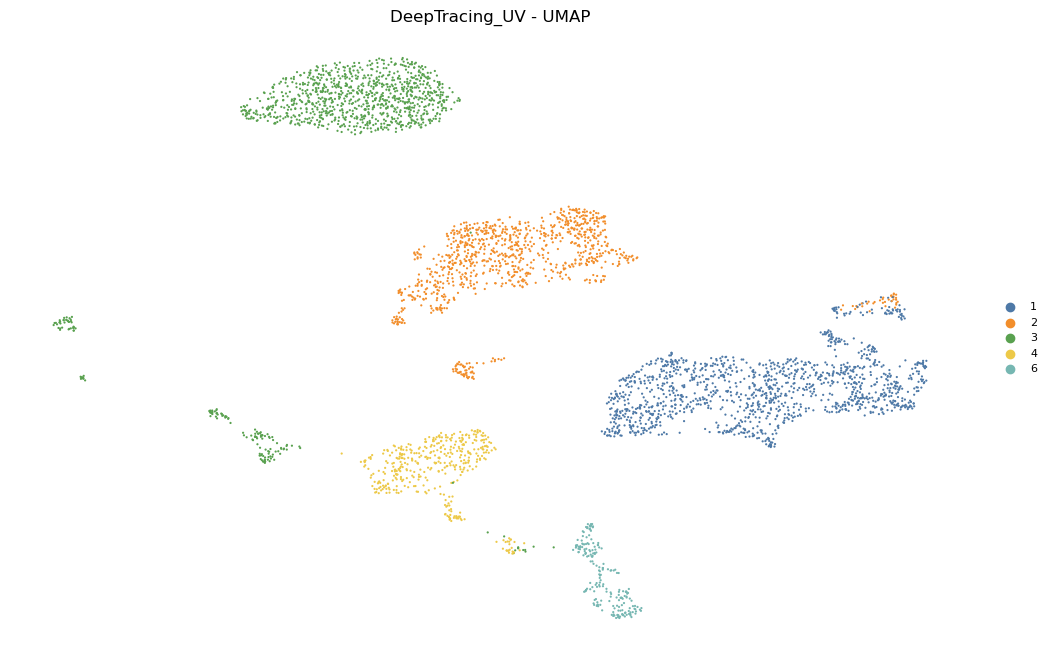

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.5/adata_embeddings_DeepTracing_UV_subtree.pdf


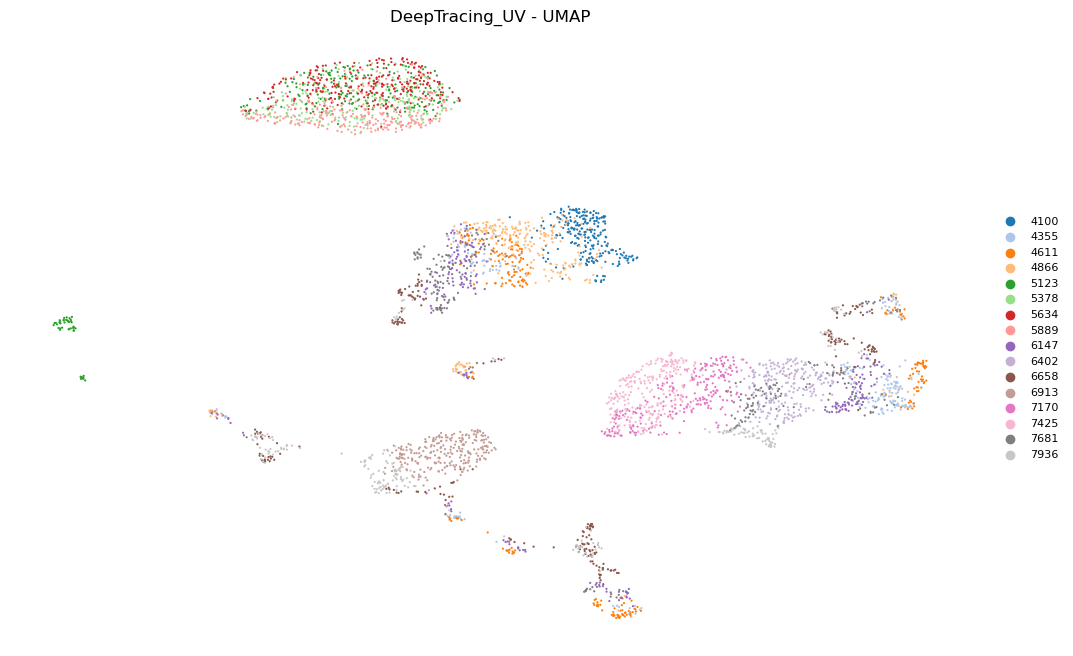

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.5/adata_embeddings_DeepTracing_LV_cluster.pdf


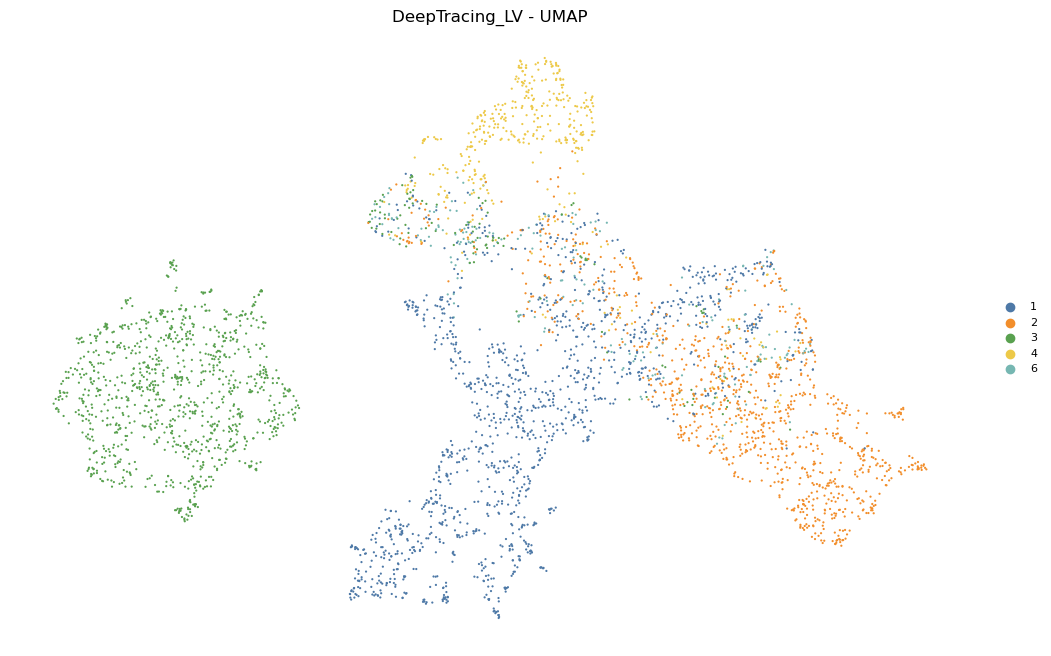

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.5/adata_embeddings_DeepTracing_LV_subtree.pdf


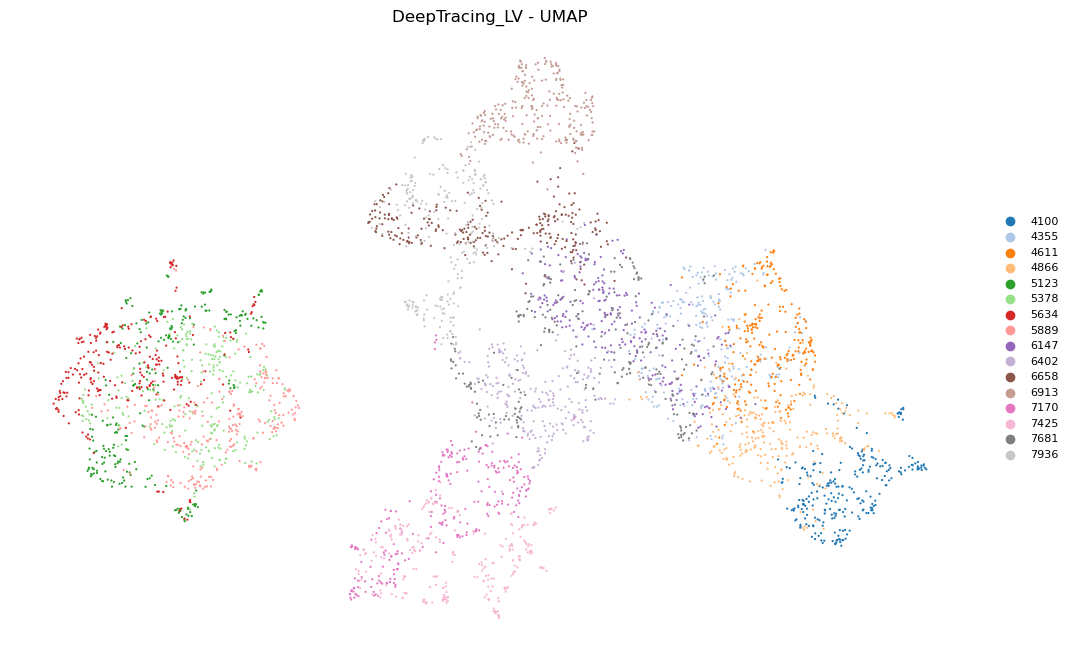

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.5/adata_embeddings_DeepTracing_IV_cluster.pdf


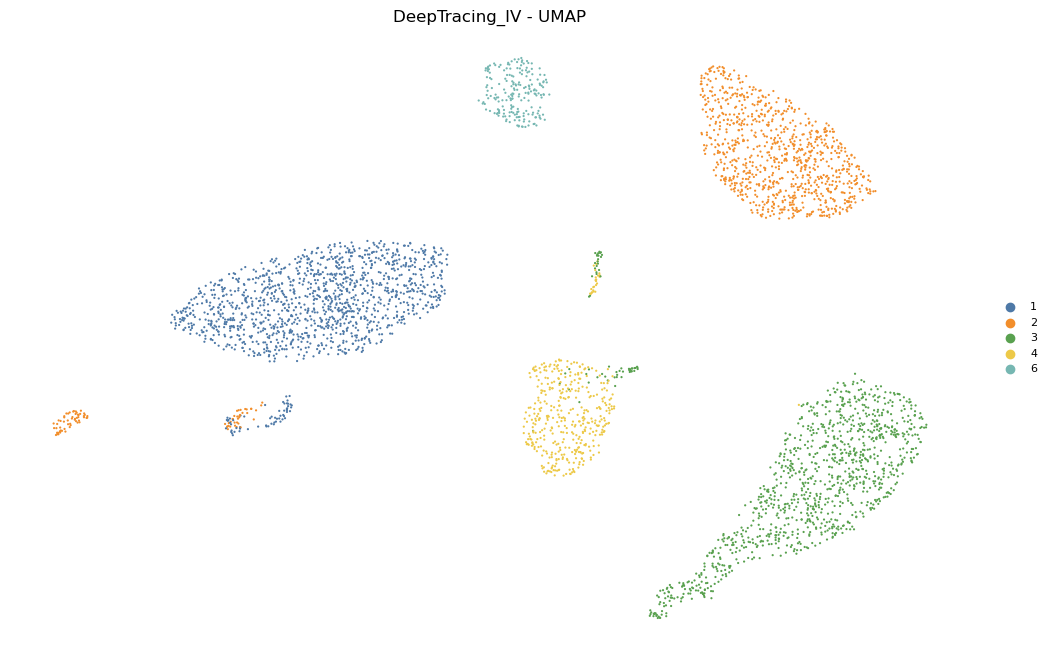

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/TedSim/results/Figures/p_a_0.5/adata_embeddings_DeepTracing_IV_subtree.pdf


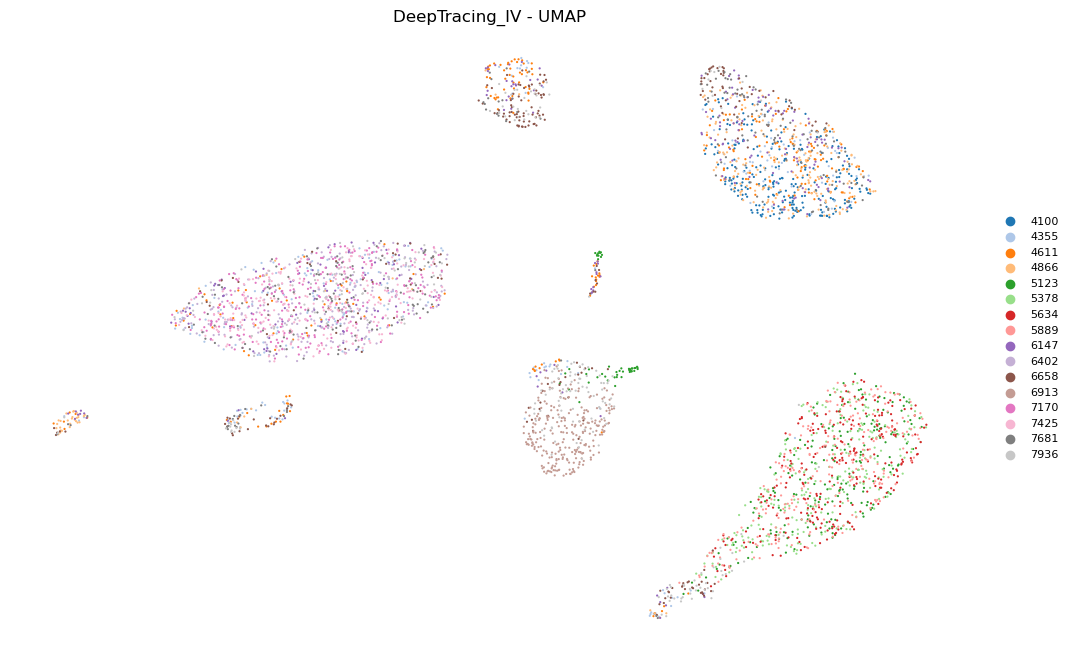

In [14]:
EMBEDDING_FILES = {
    "DeepTracing_UV": FINAL_LATENT_FILE,
    "DeepTracing_LV": GP_LATENT_FILE,
    "DeepTracing_IV": GAUSSIAN_LATENT_FILE,
}

# The plotting/evaluation helpers expect mapping values that represent paths.
adata = add_embeddings(adata, {k: str(v) for k, v in EMBEDDING_FILES.items()})
plot_umap_embeddings(
    adata,
    rep_keys=["DeepTracing_UV", "DeepTracing_LV", "DeepTracing_IV"],
    color_keys=["cluster", "subtree"],
    output_dir=FIGURES_DIR,
)